# E-Commerce Funnel Analysis – View to Purchase

**Dataset:** [eCommerce Events History in Cosmetics Shop](https://www.kaggle.com/datasets/mkechinov/ecommerce-events-history-in-cosmetics-shop) (Kaggle) — files `2020-Jan.csv` and `2020-Feb.csv`.

**Goal:** build a view → cart → purchase funnel from raw event-level data, measure conversion and drop-off at each stage, and compare funnel performance across product categories, brands and months.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Seaborn theme for all charts in the notebook
sns.set_theme(style="whitegrid")

## 1. Load and combine data

The files are large (millions of rows), so only the 7 columns needed for the analysis are loaded. `category_id` and `user_session` are not used.

In [2]:
# Columns used in the analysis
cols = ["event_time", "event_type", "product_id", "category_code", "brand", "price", "user_id"]

# Load both months
jan = pd.read_csv("data/2020-Jan.csv", usecols=cols)
feb = pd.read_csv("data/2020-Feb.csv", usecols=cols)

print("January rows:", len(jan))
print("February rows:", len(feb))

January rows: 4264752
February rows: 4156682


In [3]:
# Stack February under January into one DataFrame and free memory
df = pd.concat([jan, feb], ignore_index=True)
del jan, feb

In [4]:
# "2020-01-01 00:00:00 UTC" -> datetime (drop the " UTC" suffix first)
df["event_time"] = pd.to_datetime(df["event_time"].str.replace(" UTC", ""), format="%Y-%m-%d %H:%M:%S")

# Month label used for the Jan vs Feb comparison
df["month"] = df["event_time"].dt.month.map({1: "Jan", 2: "Feb"})

In [5]:
# Size, column types and missing values
print("Total rows:", len(df))
print()
df.info()
print()
print(df.isna().sum())
df.head()

Total rows: 8421434

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8421434 entries, 0 to 8421433
Data columns (total 8 columns):
 #   Column         Dtype         
---  ------         -----         
 0   event_time     datetime64[ns]
 1   event_type     object        
 2   product_id     int64         
 3   category_code  object        
 4   brand          object        
 5   price          float64       
 6   user_id        int64         
 7   month          object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(4)
memory usage: 514.0+ MB

event_time             0
event_type             0
product_id             0
category_code    8269530
brand            3601538
price                  0
user_id                0
month                  0
dtype: int64


,event_time,event_type,product_id,category_code,brand,price,user_id,month
0,2020-01-01 00:00:00,view,5809910,NaN,grattol,5.24,595414620,Jan
1,2020-01-01 00:00:09,view,5812943,NaN,kinetics,3.97,595414640,Jan
2,2020-01-01 00:00:19,view,5798924,NaN,zinger,3.97,595412617,Jan
3,2020-01-01 00:00:24,view,5793052,NaN,NaN,4.92,420652863,Jan
4,2020-01-01 00:00:25,view,5899926,NaN,NaN,3.92,484071203,Jan


**Data check:** 8.42M rows in total. `category_code` is missing in ~98.2% of rows and `brand` in ~42.8%. Missing values are not filled — they are only dropped inside the category and brand steps. The main funnel uses `event_type` and `user_id`, which have no missing values.

## 2. Event type distribution

In [6]:
# Count and share of every event type in the raw data
event_dist = pd.DataFrame({
    "count": df["event_type"].value_counts(),
    "percent": (df["event_type"].value_counts(normalize=True) * 100).round(2)
})
print("All event types:")
print(event_dist)

All event types:
                    count  percent
event_type                        
view              3991194    47.39
cart              2297017    27.28
remove_from_cart  1627433    19.32
purchase           505790     6.01


In [7]:
# Keep only the 3 funnel stages
funnel_stages = ["view", "cart", "purchase"]
df = df[df["event_type"].isin(funnel_stages)].copy()

print("\nRows after filtering:", len(df))


Rows after filtering: 6794001


In [8]:
# Distribution within the 3 funnel stages
stage_dist = pd.DataFrame({
    "count": df["event_type"].value_counts(),
    "percent": (df["event_type"].value_counts(normalize=True) * 100).round(2)
})
print("\nFunnel event types:")
print(stage_dist)


Funnel event types:
              count  percent
event_type                  
view        3991194    58.75
cart        2297017    33.81
purchase     505790     7.44


## 3. Funnel: unique users per stage

- Stage 1: viewed at least 1 product
- Stage 2: added at least 1 product to cart
- Stage 3: completed at least 1 purchase

In [9]:
# events = all rows per stage, users = distinct user_id per stage
funnel = (df.groupby("event_type")
            .agg(events=("user_id", "size"),
                 users=("user_id", "nunique"))
            .reindex(funnel_stages))  # keep funnel order: view -> cart -> purchase

# Average number of events per user at each stage
funnel["events_per_user"] = (funnel["events"] / funnel["users"]).round(2)
print(funnel)

             events   users  events_per_user
event_type                                  
view        3991194  716987             5.57
cart        2297017  162035            14.18
purchase     505790   49473            10.22


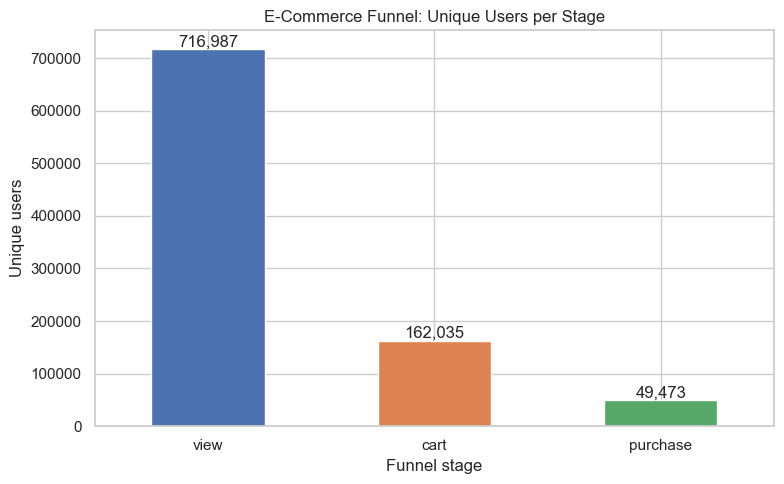

In [10]:
# Chart 1: unique users per funnel stage
fig, ax = plt.subplots(figsize=(8, 5))
funnel["users"].plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("E-Commerce Funnel: Unique Users per Stage")
ax.set_xlabel("Funnel stage")
ax.set_ylabel("Unique users")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0], fmt="{:,.0f}")  # exact count above each bar
plt.tight_layout()
plt.savefig("images/funnel_users.png", dpi=150)
plt.show()

3.99M view events come from only ~717K users. Cart users have ~14 cart events each, which points to heavy add/remove behaviour in the cart.

## 4. Conversion rates and drop-off

```
view → cart     = cart users / view users × 100
cart → purchase = purchase users / cart users × 100
view → purchase = purchase users / view users × 100
drop-off        = 100 − conversion rate
```

In [11]:
# Unique users per stage, taken from the funnel table
view_users = funnel.loc["view", "users"]
cart_users = funnel.loc["cart", "users"]
purchase_users = funnel.loc["purchase", "users"]

In [12]:
# Conversion rates (%)
view_to_cart = cart_users / view_users * 100
cart_to_purchase = purchase_users / cart_users * 100
view_to_purchase = purchase_users / view_users * 100

In [13]:
# Conversion and drop-off side by side
conversion = pd.DataFrame({
    "conversion_rate_%": [view_to_cart, cart_to_purchase, view_to_purchase],
    "drop_off_%": [100 - view_to_cart, 100 - cart_to_purchase, 100 - view_to_purchase]
}, index=["view → cart", "cart → purchase", "view → purchase (overall)"]).round(2)

print(conversion)

                           conversion_rate_%  drop_off_%
view → cart                            22.60       77.40
cart → purchase                        30.53       69.47
view → purchase (overall)               6.90       93.10


## 5. Funnel by category (top 8 by view count)

In [14]:
# Only rows with a category can be grouped by category
cat_df = df.dropna(subset=["category_code"])

In [15]:
# Top 8 categories by number of view events
top8 = (cat_df[cat_df["event_type"] == "view"]["category_code"]
        .value_counts()
        .head(8)
        .index)

cat_df = cat_df[cat_df["category_code"].isin(top8)]

In [16]:
# Unique users per category and stage; stages become columns
cat_funnel = (cat_df.groupby(["category_code", "event_type"])["user_id"]
                .nunique()
                .unstack()
                .reindex(columns=funnel_stages)
                .fillna(0))  # no users at a stage = 0

In [17]:
# Conversion rates per category
cat_funnel["view_to_cart_%"] = cat_funnel["cart"] / cat_funnel["view"] * 100
cat_funnel["cart_to_purchase_%"] = cat_funnel["purchase"] / cat_funnel["cart"] * 100
cat_funnel["view_to_purchase_%"] = cat_funnel["purchase"] / cat_funnel["view"] * 100

# Best overall conversion first
cat_funnel = cat_funnel.sort_values("view_to_purchase_%", ascending=False).round(2)
print(cat_funnel)

event_type                        view  cart  purchase  view_to_cart_%  \
category_code                                                            
apparel.glove                     4965  4128      1932           83.14   
stationery.cartrige               4313  2265      1025           52.52   
furniture.bathroom.bath           3602  1164       384           32.32   
appliances.environment.vacuum    15431  3883      1366           25.16   
appliances.personal.massager      1335   151        35           11.31   
appliances.personal.hair_cutter   1141   113        28            9.90   
furniture.living_room.cabinet     5377   760       119           14.13   
accessories.bag                   3147   146        45            4.64   

event_type                       cart_to_purchase_%  view_to_purchase_%  
category_code                                                            
apparel.glove                                 46.80               38.91  
stationery.cartrige                  

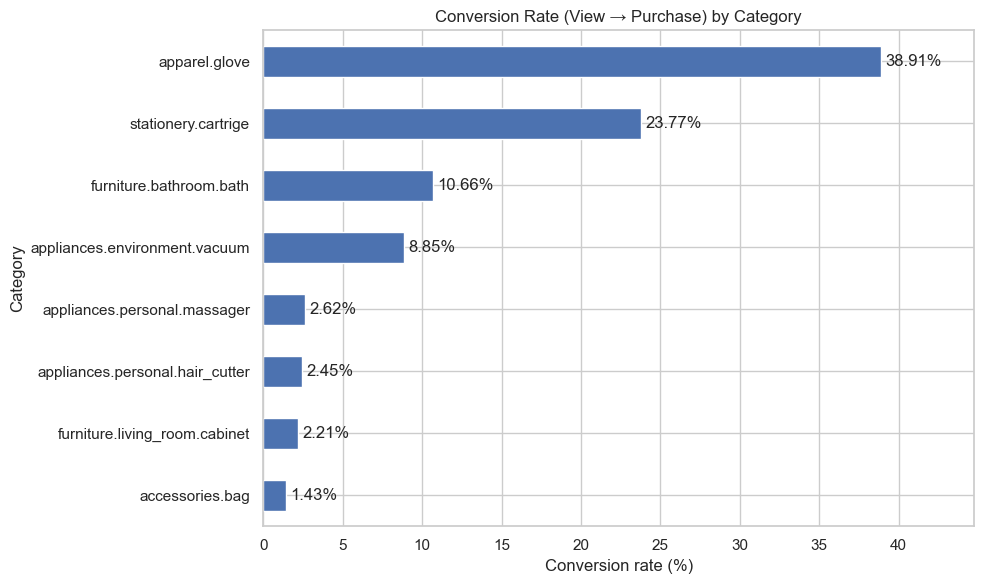

In [18]:
# Chart 2: overall conversion rate by category
fig, ax = plt.subplots(figsize=(10, 6))
cat_funnel["view_to_purchase_%"].sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Conversion Rate (View → Purchase) by Category")
ax.set_xlabel("Conversion rate (%)")
ax.set_ylabel("Category")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.set_xlim(0, cat_funnel["view_to_purchase_%"].max() * 1.15)  # room for the labels
plt.tight_layout()
plt.savefig("images/conversion_by_category.png", dpi=150)
plt.show()

## 6. January vs February

Rates are compared instead of counts, because February 2020 had 29 days and January 31.

In [19]:
# Unique users per month and stage
month_funnel = (df.groupby(["month", "event_type"])["user_id"]
                  .nunique()
                  .unstack()
                  .reindex(index=["Jan", "Feb"], columns=funnel_stages))

In [20]:
# Conversion rates per month
month_funnel["view_to_cart_%"] = month_funnel["cart"] / month_funnel["view"] * 100
month_funnel["cart_to_purchase_%"] = month_funnel["purchase"] / month_funnel["cart"] * 100
month_funnel["view_to_purchase_%"] = month_funnel["purchase"] / month_funnel["view"] * 100
month_funnel = month_funnel.round(2)
print(month_funnel)

event_type    view   cart  purchase  view_to_cart_%  cart_to_purchase_%  \
month                                                                     
Jan         397775  92653     28220           23.29               30.46   
Feb         379246  89269     25759           23.54               28.86   

event_type  view_to_purchase_%  
month                           
Jan                       7.09  
Feb                       6.79  


In [21]:
# Change from January to February in percentage points 
rate_cols = ["view_to_cart_%", "cart_to_purchase_%", "view_to_purchase_%"]
change_pp = (month_funnel.loc["Feb", rate_cols] - month_funnel.loc["Jan", rate_cols]).round(2)
print("\nChange Feb vs Jan (pp):")
print(change_pp)


Change Feb vs Jan (pp):
event_type
view_to_cart_%        0.25
cart_to_purchase_%   -1.60
view_to_purchase_%   -0.30
dtype: float64


In [22]:
# Users active in both months are counted once in each month
months_per_user = df.groupby("user_id")["month"].nunique()
print("Users active in both months:", (months_per_user == 2).sum())

Users active in both months: 63487


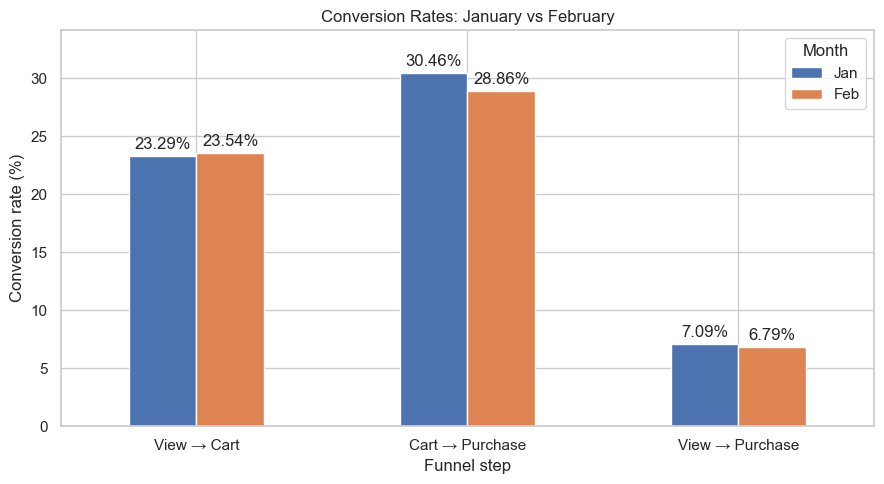

In [23]:
# Chart 3: Jan vs Feb conversion rates
fig, ax = plt.subplots(figsize=(9, 5))
month_funnel[rate_cols].T.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])  # .T: funnel steps on the x-axis
ax.set_title("Conversion Rates: January vs February")
ax.set_xlabel("Funnel step")
ax.set_ylabel("Conversion rate (%)")
ax.set_xticklabels(["View → Cart", "Cart → Purchase", "View → Purchase"], rotation=0)
ax.legend(title="Month")
for container in ax.containers:  # one container per month
    ax.bar_label(container, fmt="%.2f%%", padding=3)
ax.set_ylim(0, month_funnel[rate_cols].max().max() * 1.12)  # room for the labels
plt.tight_layout()
plt.savefig("images/jan_vs_feb_conversion.png", dpi=150)
plt.show()

## 7. Top 10 brands by purchase count

Brands are ranked by purchase **events** (items sold); the view → purchase rate uses **unique users**, like the main funnel.

In [24]:

brand_df = df.dropna(subset=["brand"])

In [25]:

purchase_counts = brand_df[brand_df["event_type"] == "purchase"]["brand"].value_counts()
top10 = purchase_counts.head(10)

In [26]:
# Unique users per stage for the top 10 brands
brand_funnel = (brand_df[brand_df["brand"].isin(top10.index)]
                  .groupby(["brand", "event_type"])["user_id"]
                  .nunique()
                  .unstack()
                  .reindex(columns=funnel_stages))

brand_funnel["purchase_count"] = top10  
brand_funnel["view_to_purchase_%"] = brand_funnel["purchase"] / brand_funnel["view"] * 100
brand_funnel = brand_funnel.sort_values("purchase_count", ascending=False).round(2)
print(brand_funnel)

event_type   view   cart  purchase  purchase_count  view_to_purchase_%
brand                                                                 
runail      86823  41747     15562           45274               17.92
irisk       70510  36384     13332           31210               18.91
grattol     48870  23339      7905           21320               16.18
masura      35640  17432      5401           19929               15.15
ingarden    23716  15001      4972           10276               20.96
estel       40234  11703      3994            8616                9.93
bpw.style   13376   8230      3070            8437               22.95
uno         22313  10845      4128            6871               18.50
italwax     19923   7456      2927            6740               14.69
kapous      42289   9068      3018            6370                7.14


In [27]:
# Share of the top 5 brands in all purchase events
top5_share = top10.head(5).sum() / (df["event_type"] == "purchase").sum() * 100
print(f"Top 5 brands share of all purchases: {top5_share:.2f}%")

Top 5 brands share of all purchases: 25.31%


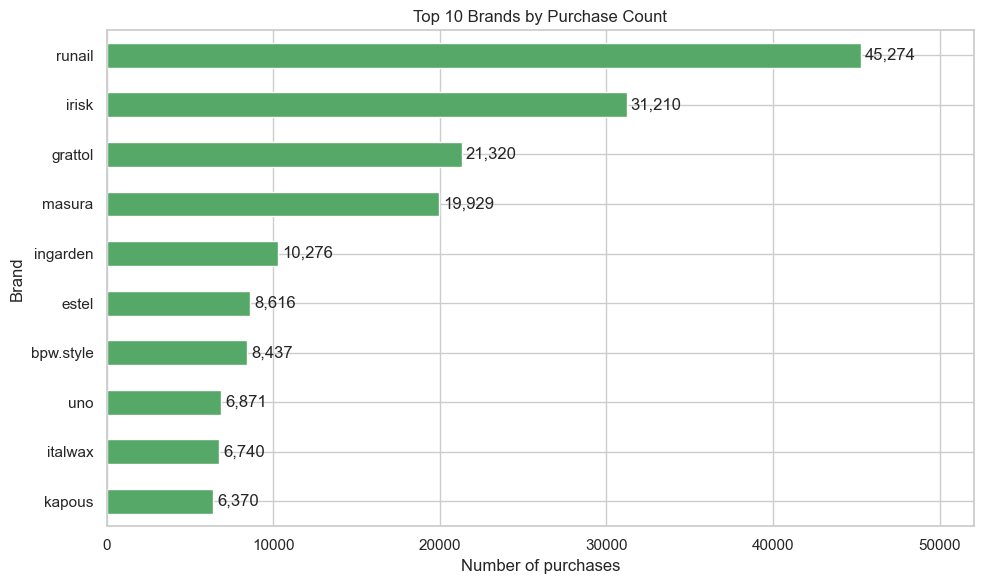

In [28]:
# Chart 4: top 10 brands by purchase count
fig, ax = plt.subplots(figsize=(10, 6))
brand_funnel["purchase_count"].sort_values().plot(kind="barh", ax=ax, color="#55A868")
ax.set_title("Top 10 Brands by Purchase Count")
ax.set_xlabel("Number of purchases")
ax.set_ylabel("Brand")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
ax.set_xlim(0, brand_funnel["purchase_count"].max() * 1.15)  # room for the labels
plt.tight_layout()
plt.savefig("images/top10_brands.png", dpi=150)
plt.show()

## 8. Price outliers in purchase events (IQR)

```
IQR   = Q3 − Q1
lower = Q1 − 1.5 × IQR
upper = Q3 + 1.5 × IQR
```

Prices outside `[lower, upper]` are outliers.

In [29]:
# Prices of purchase events only
purchase_prices = df.loc[df["event_type"] == "purchase", "price"]
print(purchase_prices.describe())

count    505790.000000
mean          4.997775
std           8.936732
min         -79.370000
25%           1.590000
50%           3.020000
75%           5.560000
max         327.780000
Name: price, dtype: float64


In [30]:
# IQR bounds
Q1 = purchase_prices.quantile(0.25)
Q3 = purchase_prices.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f"\nQ1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower bound: {lower:.2f}")
print(f"Upper bound: {upper:.2f}")


Q1: 1.59
Q3: 5.56
IQR: 3.97
Lower bound: -4.37
Upper bound: 11.52


In [31]:
# Outliers 
outliers = purchase_prices[(purchase_prices < lower) | (purchase_prices > upper)]
print(f"\nOutliers: {len(outliers)} of {len(purchase_prices)} purchases "
      f"({len(outliers) / len(purchase_prices) * 100:.2f}%)")
print(f"Max price: {purchase_prices.max():.2f}")


Outliers: 34947 of 505790 purchases (6.91%)
Max price: 327.78


In [32]:
# Price sanity check: a purchase price should never be zero or negative
print("Purchases with price <= 0:", (purchase_prices <= 0).sum())
print("Low-side outliers (< lower):", (purchase_prices < lower).sum())
print("High-side outliers (> upper):", (purchase_prices > upper).sum())

Purchases with price <= 0: 72
Low-side outliers (< lower): 71
High-side outliers (> upper): 34876


## 9. Bonus: time from first view to first purchase

For every buyer: first view time and first purchase time. Only buyers whose first view comes before (or at) their first purchase are kept.

In [33]:
# Earliest view and earliest purchase per user
first_view = df[df["event_type"] == "view"].groupby("user_id")["event_time"].min()
first_purchase = df[df["event_type"] == "purchase"].groupby("user_id")["event_time"].min()

In [34]:
# Side by side; dropna keeps only users who have both a view and a purchase
time_df = pd.concat([first_view, first_purchase], axis=1,
                    keys=["first_view", "first_purchase"]).dropna()

# Drop buyers whose purchase appears before their first view in Jan-Feb

time_df = time_df[time_df["first_purchase"] >= time_df["first_view"]]

# Time difference in hours
time_df["hours_to_purchase"] = (time_df["first_purchase"] - time_df["first_view"]).dt.total_seconds() / 3600

In [35]:
# Distribution of time to purchase; median is more robust than mean here
print("Converted users:", len(time_df))
print(time_df["hours_to_purchase"].describe())
print(f"\nMean: {time_df['hours_to_purchase'].mean():.2f} hours "
      f"({time_df['hours_to_purchase'].mean() / 24:.2f} days)")
print(f"Median: {time_df['hours_to_purchase'].median():.2f} hours")

Converted users: 45571
count    45571.000000
mean       131.808645
std        245.071310
min          0.000000
25%          0.403056
50%          4.533889
75%        144.486528
max       1415.913333
Name: hours_to_purchase, dtype: float64

Mean: 131.81 hours (5.49 days)
Median: 4.53 hours


Half of buyers purchase within ~4.5 hours of their first view (a quarter within ~24 minutes), but a quarter take more than 6 days. The mean (5.49 days) is pulled up by these slow buyers, so the median describes the typical buyer better.

## 10. Bonus: high view, low conversion products

"High view" = top 5% of products by unique viewers (95th percentile).

In [36]:
# Mini funnel per product
product_stats = (df.groupby(["product_id", "event_type"])["user_id"]
                   .nunique()
                   .unstack()
                   .reindex(columns=funnel_stages)
                   .fillna(0))

product_stats["view_to_purchase_%"] = product_stats["purchase"] / product_stats["view"] * 100

In [37]:
# Keep only the most viewed 5% of products
view_threshold = product_stats["view"].quantile(0.95)
high_view = product_stats[product_stats["view"] >= view_threshold]
print(f"High-view threshold: {view_threshold:.0f} viewers")
print(f"High-view products: {len(high_view)}")

High-view threshold: 213 viewers
High-view products: 2530


In [38]:
# Add the brand of each product for context 
product_brand = df.groupby("product_id")["brand"].first()
high_view = high_view.join(product_brand)

In [39]:
# How many high-view products had no purchase at all?
zero_sales = (high_view["purchase"] == 0).sum()
print(f"High-view products with zero purchases: {zero_sales}")


low_conv = (high_view.sort_values(["view_to_purchase_%", "view"], ascending=[True, False])
                     .head(10).round(2))
print(low_conv)

High-view products with zero purchases: 22
             view  cart  purchase  view_to_purchase_%     brand
product_id                                                     
27759       712.0   0.0       0.0                 0.0    masura
5678162     553.0   0.0       0.0                 0.0      None
5906219     462.0  24.0       0.0                 0.0    strong
5893947     444.0   0.0       0.0                 0.0    masura
5894358     419.0   8.0       0.0                 0.0      None
5703199     393.0   8.0       0.0                 0.0   metzger
5706830     386.0  19.0       0.0                 0.0      None
5894359     374.0   5.0       0.0                 0.0      None
5770134     357.0  11.0       0.0                 0.0  kosmekka
59872       351.0   0.0       0.0                 0.0    masura


## 11. Key insights for the product / growth team

1. **The biggest leak is the first step.** 77.4% of viewers never add anything to the cart. Better product pages (photos, descriptions, price visibility) have the largest potential.
2. **The cart is used like a wishlist.** Cart users add to the cart ~14 times on average, `remove_from_cart` events equal ~71% of cart events, and only 30.5% of cart users buy. Cart reminders could turn more of this intent into purchases.
3. **February got worse at checkout, not at interest.** Overall conversion fell by 0.30 pp because cart → purchase dropped by 1.60 pp while view → cart slightly improved.
4. **Some products and brands get attention but not sales.** Vacuums, kapous and estel are heavily viewed but convert poorly, while bpw.style converts best with the fewest views. 22 high-view products sold nothing.
5. **Half of buyers decide within hours, a quarter needs a week or more.** Retargeting during the first week after the first visit can win back slow deciders.

More detail in `note.md`.